# Online Retail Sales Analysis
**Objective:** Analyse online retail transactions (Dec 2010 to Dec 2011) to find top products, countries, customers, monthly trends and customer behaviour.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\acer\Downloads\online_retail_sales.csv")
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

## Data Cleaning
- Removed duplicate rows
- Removed cancelled invoices and returns
- Removed rows with zero price
- Removed non-product rows (postage, manual entries, bank charges)
- Removed 2 very large orders that were cancelled later
- Created Sales = Quantity x Price
- Customer analysis uses only rows with a Customer ID (about 25% of rows have none)

In [3]:
print("Before cleaning:", df.shape)

df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="mixed")

Before cleaning: (541910, 8)


In [4]:
# remove cancellations and returns
df = df[~df["Invoice"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

# remove non-product rows
df = df[~df["Description"].str.contains(
    "POSTAGE|MANUAL|BANK CHARGES|CARRIAGE|DOTCOM", case=False, na=False
)]

df["Sales"] = df["Quantity"] * df["Price"]

# customer analysis-ku mattum (guest orders remove)
customer_df = df.dropna(subset=["Customer ID"])

print("After cleaning:", df.shape)
print("Total revenue:", round(df["Sales"].sum()))

print(df[df["Quantity"] > 50000][["Invoice", "Description", "Quantity", "Sales", "Customer ID"]])

df = df[df["Quantity"] < 50000]
customer_df = df.dropna(subset=["Customer ID"])
print("Total revenue:", round(df["Sales"].sum()))

After cleaning: (522364, 9)
Total revenue: 10269437
       Invoice                     Description  Quantity     Sales  \
61619   541431  MEDIUM CERAMIC TOP STORAGE JAR     74215   77183.6   
540421  581483     PAPER CRAFT , LITTLE BIRDIE     80995  168469.6   

        Customer ID  
61619       12346.0  
540421      16446.0  
Total revenue: 10023784


## Analysis

In [5]:
df.duplicated().sum()
df.dtypes
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
PACK OF 12 LONDON TISSUES             26119
PACK OF 60 PINK PAISLEY CAKE CASES    24820
Name: Quantity, dtype: int64


In [6]:
print("Cancelled invoices left:", df["Invoice"].astype(str).str.startswith("C").sum())
print("Zero/negative price rows left:", (df["Price"] <= 0).sum())


Cancelled invoices left: 0
Zero/negative price rows left: 0


In [7]:
   df.duplicated().sum()
   df = df.drop_duplicates()
   df.shape

   print("Before cleaning:", df.shape)

   df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])


Before cleaning: (522362, 9)


In [8]:
df["Customer ID"].nunique()
df["Country"].value_counts().head(10)
country_sales = df.groupby("Country")["Sales"].sum()
country_sales.sort_values(ascending=False).head(10)


Country
United Kingdom    8501081.043
Netherlands        283889.340
EIRE               270797.660
Germany            205381.150
France             184493.000
Australia          138103.810
Spain               55706.560
Switzerland         53065.600
Japan               37416.370
Belgium             36927.340
Name: Sales, dtype: float64

In [9]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Sales"].sum()
print(monthly_sales)

product_sales = df.groupby("Description")["Sales"].sum()
print(product_sales.sort_values(ascending=False).head(10))

customer_sales = customer_df.groupby("Customer ID")["Sales"].sum()
print(customer_sales.sort_values(ascending=False).head(10))

customer_orders = customer_df.groupby("Customer ID")["Invoice"].nunique()
print(customer_orders.sort_values(ascending=False).head(10))


Month
2010-12     789178.840
2011-01     593021.290
2011-02     507780.070
2011-03     690052.440
2011-04     515407.991
2011-05     739811.650
2011-06     737126.680
2011-07     687959.601
2011-08     735012.850
2011-09    1028036.761
2011-10    1103073.170
2011-11    1451582.090
2011-12     445740.160
Freq: M, Name: Sales, dtype: float64
Description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
Name: Sales, dtype: float64
Customer ID
14646.0    279138.02
18102.0    259657.30
17450.0    194390.79
14911.0    136108.63
12415.0    124564.53
14156.0    116560.08


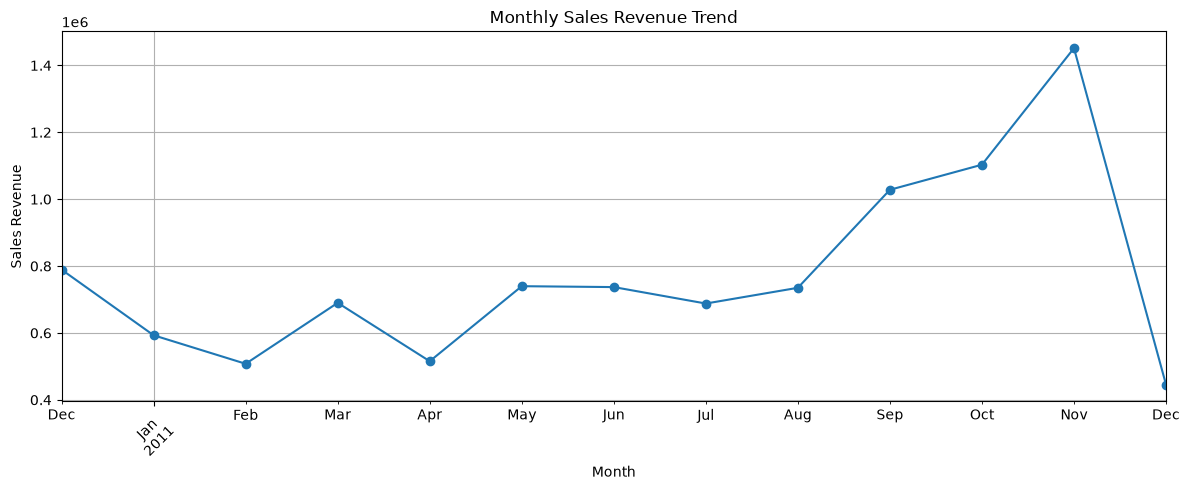

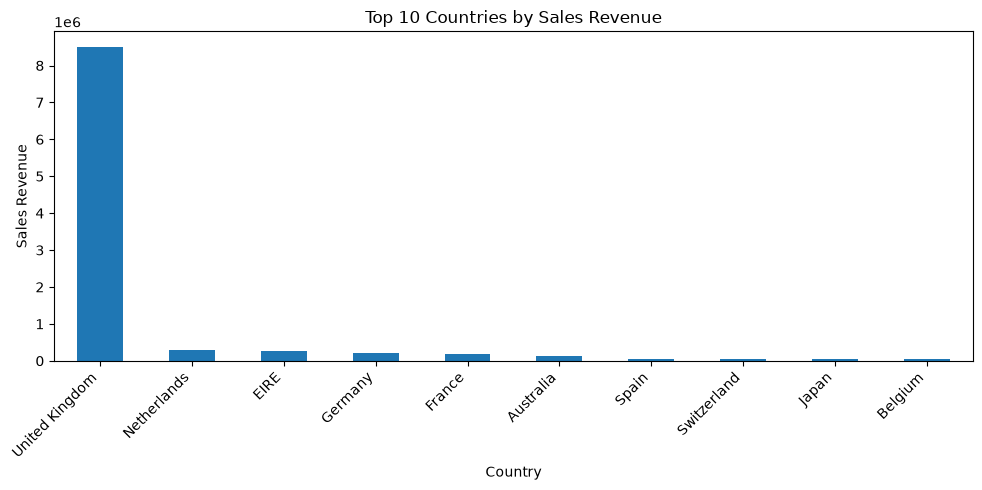

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Sales', 'Month'],
      dtype='str')

In [10]:
import matplotlib.pyplot as plt
monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

country_sales = df.groupby("Country")["Sales"].sum()

top_countries = country_sales.sort_values(
    ascending=False
).head(10)

top_countries.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Country")
plt.ylabel("Sales Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
df.columns

In [11]:
import numpy as np
average_sales = np.mean(df["Sales"])
median_sales = np.median(df["Sales"])
print("Average_sales:", round(average_sales))
print("Median_sales:", round(median_sales))

min_sales = np.min(df["Sales"])
max_sales = np.max(df["Sales"])
print("Min_sales:", (min_sales))
print("Max_sales:", (max_sales))
df.loc[df["Sales"].idxmin()]
df.loc[df["Sales"].idxmax()]


Average_sales: 19
Median_sales: 10
Min_sales: 0.001
Max_sales: 38970.0


Invoice                                556444
StockCode                               22502
Description    PICNIC BASKET WICKER 60 PIECES
Quantity                                   60
InvoiceDate               2011-06-10 15:28:00
Price                                   649.5
Customer ID                           15098.0
Country                        United Kingdom
Sales                                 38970.0
Month                                 2011-06
Name: 222671, dtype: object

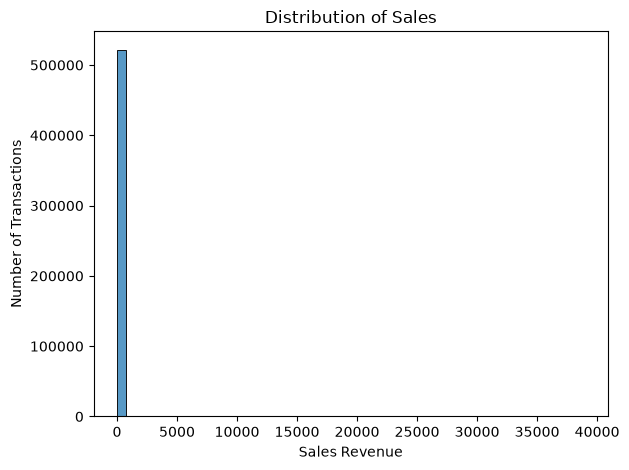

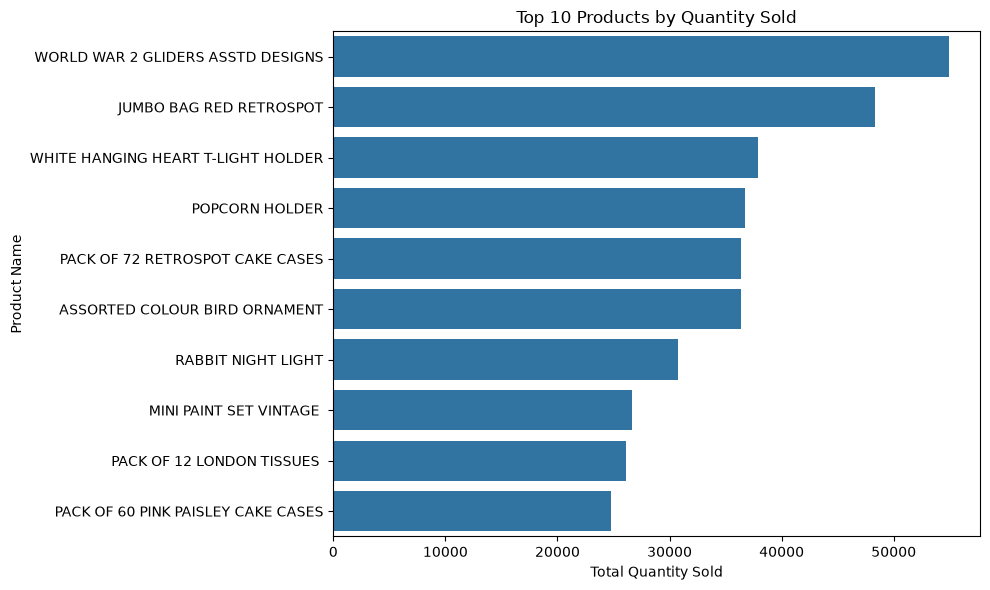

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x="Sales", bins=50)

plt.title("Distribution of Sales")
plt.xlabel("Sales Revenue")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()



Repeat Customers      2828
One-Time Customers    1505
dtype: int64


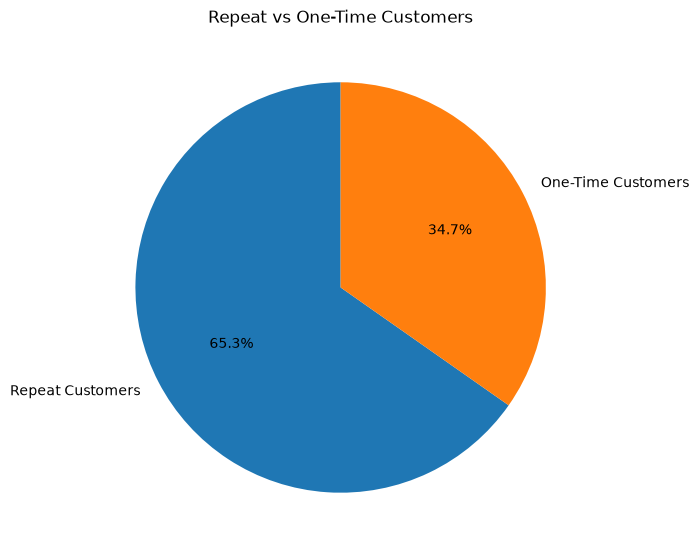

In [13]:
customer_orders = customer_df.groupby("Customer ID")["Invoice"].nunique()

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

customer_type = pd.Series({
    "Repeat Customers": repeat_customers,
    "One-Time Customers": one_time_customers
})

print(customer_type)

plt.figure(figsize=(7, 7))

plt.pie(
    customer_type.values,
    labels=customer_type.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Repeat vs One-Time Customers")

plt.tight_layout()
plt.show()

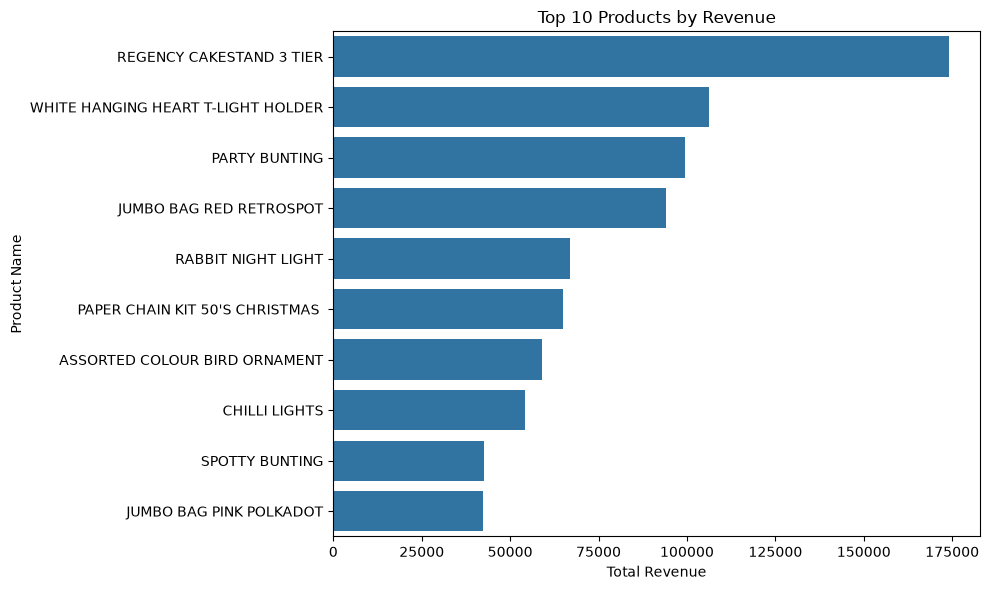

In [14]:
top_revenue_products = product_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_revenue_products.values, y=top_revenue_products.index)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

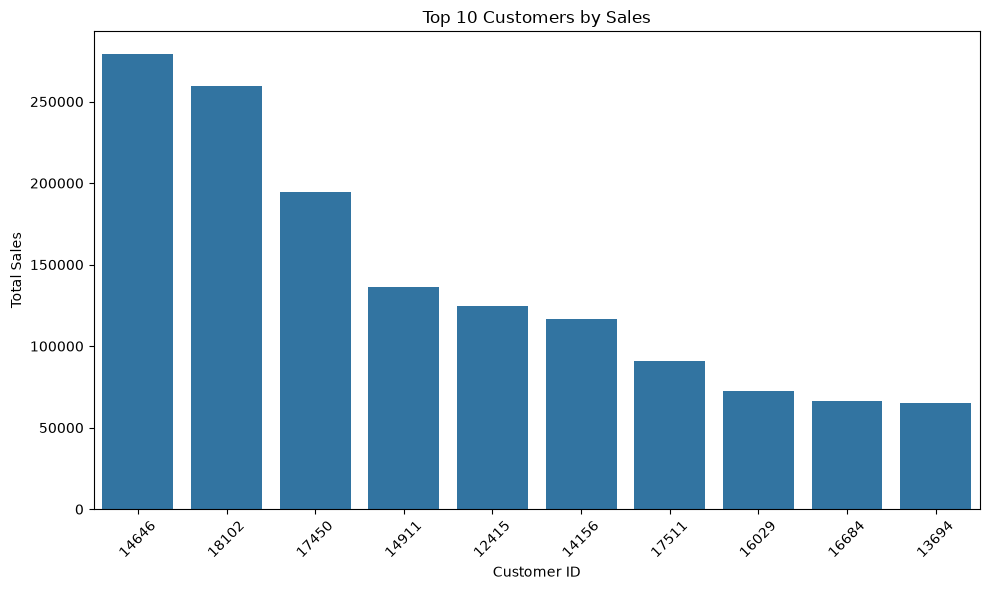

In [15]:
top_customers = customer_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_customers.index.astype(int).astype(str), y=top_customers.values)
plt.title("Top 10 Customers by Sales")
plt.xlabel("Customer ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
df["Day"] = df["InvoiceDate"].dt.day_name()

day_sales = df.groupby("Day")["Sales"].sum()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_sales = day_sales.reindex(day_order).fillna(0)

print(day_sales)



Day
Monday       1682467.210
Tuesday      2020944.911
Wednesday    1781804.860
Thursday     2131177.150
Friday       1609298.711
Saturday           0.000
Sunday        798090.751
Name: Sales, dtype: float64


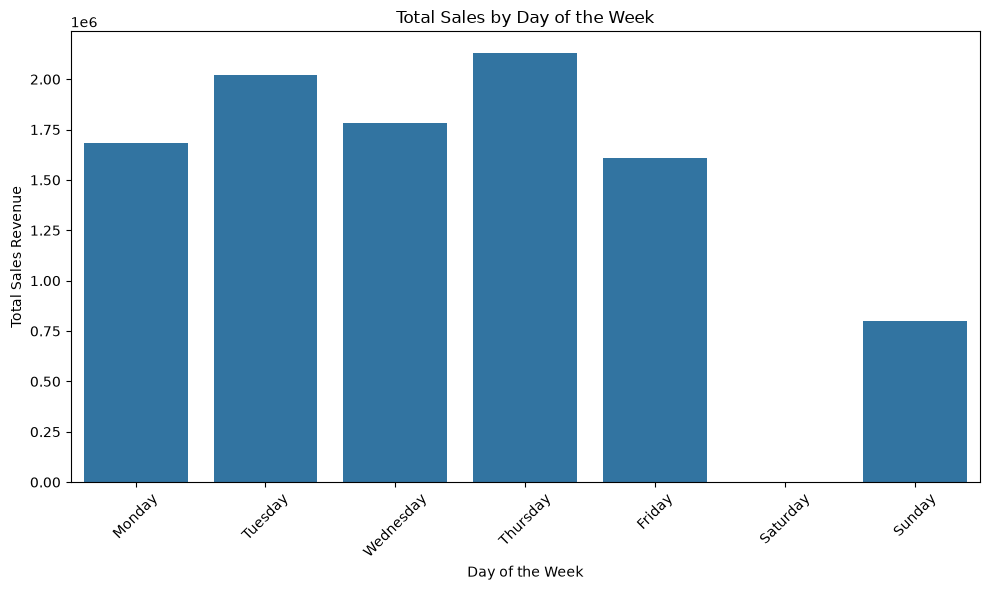

In [17]:
plt.figure(figsize=(10, 6))
sns.barplot(x=day_sales.index, y=day_sales.values)
plt.title("Total Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Key Findings
- After cleaning, the data has **522,362 transaction lines** with total revenue of about **10.02M**.
- The **United Kingdom** generates about **85%** of revenue (8.50M). Netherlands, EIRE, Germany and France follow, each below 3%.
- Sales grow strongly in the last quarter: **September 1.03M, October 1.10M, November 1.45M** (peak). **February** is the weakest full month (0.51M). December 2011 is incomplete because the data ends on 9 Dec.
- **Regency Cakestand 3 Tier** is the top product by revenue (174K). **World War 2 Gliders** has the highest quantity sold (54,951).
- The top customer (ID 14646) spent about **279K**, around 2.8% of total revenue.
- About **65%** of customers with an ID are repeat customers (2,828 of 4,333).
- **Thursday** is the best sales day (2.13M) and **Sunday** the lowest (0.80M). No transactions are recorded on Saturdays.